In [14]:
import mne
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as mp
from glob import glob
from pathlib import Path
from scipy.ndimage import zoom
from PIL import Image
import os
import re
import torch.nn as nn
from sklearn.model_selection import train_test_split
import random
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
import copy

In [64]:
base_dir=r"H:\Paper_1\Features\Amplitude_Based\AEC_Class\AEC"

def load_all_bands_per_subject(base_dir, bands_list, group_name, dtype=np.float32):
    subjects={}

    for band in bands_list:
        band_dir=os.path.join(base_dir, band, group_name)
        for fname in sorted(os.listdir(band_dir)):
            if not fname.endswith(".png"):
                continue

            #fname: subjX_winY.png
            name=fname[:-4]
            subj_part, _ =name.split("_")
            subj_id=int(subj_part[4:])

            img=np.asarray(Image.open(os.path.join(band_dir, fname)), dtype=dtype)

            #Initialize dict for subject if not exists
            if subj_id not in subjects:
                subjects[subj_id]={}
            #Append image to the correct band
            subjects[subj_id].setdefault(band, []).append(img)

    #Convert lists to arrays
    all_subjects=[]
    for subj_id in sorted(subjects):
        subj_dict={}
        for band in bands_list:
            subj_dict[band]=np.stack(subjects[subj_id][band])  #shape: (num_windows, H, W)
        all_subjects.append(subj_dict)

    return all_subjects

#Usage
bands_list=["alpha", "beta", "delta","gamma", "theta"]
scz_dfc=load_all_bands_per_subject(base_dir, bands_list, "SCZ")
hc_dfc=load_all_bands_per_subject(base_dir, bands_list, "HC")

#Example
print(scz_dfc[0]['alpha'].shape)  #(num_windows, H, W)

(621, 128, 128)


In [65]:
def normalize_subjects_minus1_to_1(subjects):
    """
    subjects: list of dicts
              subjects[i][band] -> (num_windows, H, W) uint8/float
    returns: normalized subjects (float32 in [-1,1])
    """
    for subj in subjects:
        for band in subj:
            x=subj[band].astype(np.float32)
            x=x / 255.0        #[0,1]
            x=x * 2.0 - 1.0    #[-1,1]
            subj[band] = x
    return subjects

scz_dfc=normalize_subjects_minus1_to_1(scz_dfc)
hc_dfc=normalize_subjects_minus1_to_1(hc_dfc)

print(scz_dfc[0]['alpha'].min(), scz_dfc[0]['alpha'].max())

-0.8352941 0.96862745


Single Band Model Pipeline

In [4]:
scz_alpha=[subj['alpha'] for subj in scz_dfc]
hc_alpha=[subj['alpha'] for subj in hc_dfc]

print(len(scz_alpha))  # number of SCZ subjects
print(scz_alpha[0].shape)

14
(621, 128, 128)


In [5]:
total_windows_scz = sum(subj.shape[0] for subj in scz_alpha)
print("Total SCZ windows:", total_windows_scz)

Total SCZ windows: 6237


In [9]:
# -------------------------------------------------
# 1️⃣ Subject labels
# -------------------------------------------------

scz_subjects = scz_alpha
hc_subjects  = hc_alpha

scz_labels = [1] * len(scz_subjects)
hc_labels  = [0] * len(hc_subjects)

all_subjects = scz_subjects + hc_subjects
all_labels   = scz_labels + hc_labels

# -------------------------------------------------
# 2️⃣ Subject-wise train-test split
# -------------------------------------------------

train_subjects, test_subjects, train_labels, test_labels = train_test_split(
    all_subjects,
    all_labels,
    test_size=0.2,
    stratify=all_labels,
    random_state=42
)

print("Train subjects:", len(train_subjects))
print("Test subjects:", len(test_subjects))

# -------------------------------------------------
# 3️⃣ Concatenate windows AFTER splitting
# -------------------------------------------------

def flatten_subjects(subject_list, label_list):
    X = []
    y = []

    for subj_data, label in zip(subject_list, label_list):
        X.append(subj_data)
        y.append(np.full(subj_data.shape[0], label))

    X = np.concatenate(X, axis=0)
    y = np.concatenate(y, axis=0)

    return X, y

X_train, y_train = flatten_subjects(train_subjects, train_labels)
X_test,  y_test  = flatten_subjects(test_subjects,  test_labels)

print("Train windows:", X_train.shape)
print("Test windows:", X_test.shape)

# -------------------------------------------------
# 4️⃣ Add channel dimension
# -------------------------------------------------

X_train = np.expand_dims(X_train, axis=1)
X_test  = np.expand_dims(X_test, axis=1)

# -------------------------------------------------
# 5️⃣ Dataset & DataLoader
# -------------------------------------------------

class AlphaDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = AlphaDataset(X_train, y_train)
test_dataset  = AlphaDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader  = DataLoader(test_dataset, batch_size=32)

Train subjects: 22
Test subjects: 6
Train windows: (10692, 128, 128)
Test windows: (3132, 128, 128)


In [58]:
from torch.utils.data import DataLoader

# Example: train_dataset is your dataset object
labels = [label for _, label in train_dataset]  # list of all labels

N_pos = sum([1 for l in labels if l == 1])
N_neg = sum([1 for l in labels if l == 0])

print("Positives:", N_pos, "Negatives:", N_neg)
print(N_pos/N_neg)

Positives: 4617 Negatives: 6075
0.76


In [59]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.05),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.15),

            # Extra shallow refinement block (important!)
            nn.Conv2d(128, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
        )


        # Adaptive pooling removes dependency on input size
        self.global_pool = nn.Sequential(nn.AdaptiveAvgPool2d((1, 1)), nn.AdaptiveMaxPool2d((1,1)))
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),  # adjust H, W
            nn.BatchNorm1d(64),
            nn.GELU(),
            nn.Dropout(0.4),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        x = self.features(x)
        x_avg = F.adaptive_avg_pool2d(x, (1,1))
        x_max = F.adaptive_max_pool2d(x, (1,1))
        x = x_avg + x_max
        x = self.classifier(x)
        return x

In [60]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = SimpleCNN().to(device)
pos_weight = torch.tensor([N_neg / N_pos]).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-5)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=3, factor=0.5)

In [61]:
def train_model(model, train_loader, test_loader, epochs=50, patience=5):

    train_losses = []
    test_losses = []
    train_accs = []
    test_accs = []
    test_aucs = []

    best_auc = 0
    patience_counter = 0
    best_model_wts = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):

        # ===================== TRAIN =====================
        model.train()
        running_loss = 0

        all_train_labels = []
        all_train_probs = []

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device).float().unsqueeze(1)

            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            probs = torch.sigmoid(outputs)

            all_train_labels.extend(labels.cpu().numpy())
            all_train_probs.extend(probs.detach().cpu().numpy())

        train_loss = running_loss / len(train_loader)
        train_losses.append(train_loss)

        train_preds = (np.array(all_train_probs) > 0.5).astype(int)
        train_labels_np = np.array(all_train_labels).astype(int)

        train_acc = accuracy_score(train_labels_np, train_preds)
        train_accs.append(train_acc)

        # ===================== VALIDATION =====================
        model.eval()
        running_loss = 0

        all_test_labels = []
        all_test_probs = []

        with torch.no_grad():
            for images, labels in test_loader:
                images = images.to(device)
                labels = labels.to(device).float().unsqueeze(1)

                outputs = model(images)
                loss = criterion(outputs, labels)

                running_loss += loss.item()

                probs = torch.sigmoid(outputs)

                all_test_labels.extend(labels.cpu().numpy())
                all_test_probs.extend(probs.cpu().numpy())

        test_loss = running_loss / len(test_loader)
        test_losses.append(test_loss)

        test_preds = (np.array(all_test_probs) > 0.5).astype(int)
        test_labels_np = np.array(all_test_labels).astype(int)

        test_acc = accuracy_score(test_labels_np, test_preds)
        test_precision = precision_score(test_labels_np, test_preds)
        test_recall = recall_score(test_labels_np, test_preds)
        test_f1 = f1_score(test_labels_np, test_preds)
        test_auc = roc_auc_score(test_labels_np, all_test_probs)

        test_accs.append(test_acc)
        test_aucs.append(test_auc)

        scheduler.step(test_auc)

        print(f"Epoch [{epoch+1}/{epochs}]")
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
        print(f"Val   Loss: {test_loss:.4f} | Test Acc: {test_acc:.4f} | "
              f"Precision: {test_precision:.4f} | Recall: {test_recall:.4f} | "
              f"F1: {test_f1:.4f} | AUC: {test_auc:.4f}")
        print("-"*60)

        # ===================== EARLY STOPPING =====================
        if test_auc > best_auc:
            best_auc = test_auc
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0
            print("✅ Best model updated")
        else:
            patience_counter += 1
            print(f"⏳ EarlyStopping counter: {patience_counter}/{patience}")

        if patience_counter >= patience:
            print("🛑 Early stopping triggered!")
            break

    # Load best model
    model.load_state_dict(best_model_wts)
    print(f"\n🎯 Best Validation AUC: {best_auc:.4f}")

    # ===================== PLOTS =====================

    mp.figure()
    mp.plot(train_losses)
    mp.plot(test_losses)
    mp.title("Loss Curve")
    mp.xlabel("Epoch")
    mp.ylabel("Loss")
    mp.legend(["Train", "Validation"])
    mp.show()

    mp.figure()
    mp.plot(train_accs)
    mp.plot(test_accs)
    mp.title("Accuracy Curve")
    mp.xlabel("Epoch")
    mp.ylabel("Accuracy")
    mp.legend(["Train", "Validation"])
    mp.show()

    return model

Epoch [1/50]
Train Loss: 0.3985 | Train Acc: 0.8550
Val   Loss: 1.1115 | Test Acc: 0.6737 | Precision: 0.8814 | Recall: 0.4265 | F1: 0.5749 | AUC: 0.7709
------------------------------------------------------------
✅ Best model updated
Epoch [2/50]
Train Loss: 0.1941 | Train Acc: 0.9404
Val   Loss: 0.7030 | Test Acc: 0.7503 | Precision: 0.7447 | Recall: 0.7870 | F1: 0.7653 | AUC: 0.8425
------------------------------------------------------------
✅ Best model updated
Epoch [3/50]
Train Loss: 0.1355 | Train Acc: 0.9578
Val   Loss: 0.8705 | Test Acc: 0.7682 | Precision: 0.9348 | Recall: 0.5932 | F1: 0.7258 | AUC: 0.8907
------------------------------------------------------------
✅ Best model updated
Epoch [4/50]
Train Loss: 0.0976 | Train Acc: 0.9723
Val   Loss: 0.6065 | Test Acc: 0.7874 | Precision: 0.7359 | Recall: 0.9185 | F1: 0.8171 | AUC: 0.9054
------------------------------------------------------------
✅ Best model updated
Epoch [5/50]
Train Loss: 0.0817 | Train Acc: 0.9741
Val 

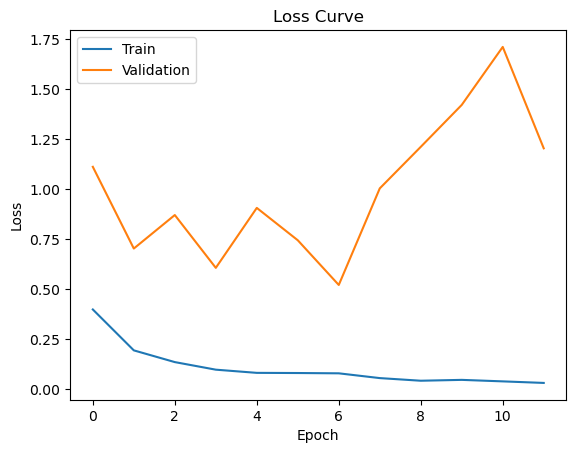

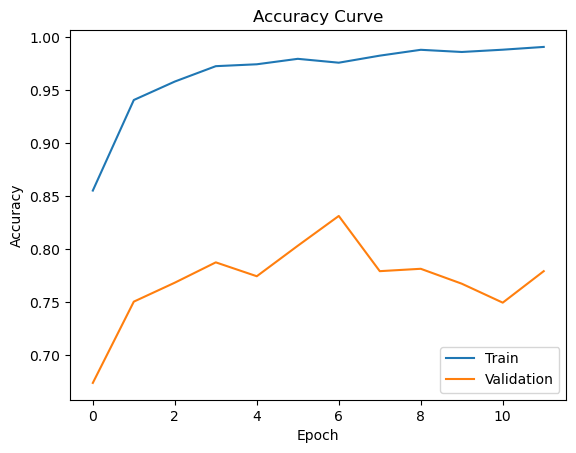

In [62]:
#train_model(model, train_loader, test_loader, epochs=100)
model=train_model(model, train_loader, test_loader, epochs=50, patience=5)

Multi Band Fusion Model Pipeline

In [66]:
bands_list = ["alpha", "beta", "delta", "gamma", "theta"]

def stack_bands(subjects, bands_list, label):
    all_windows = []
    all_labels = []
    all_subject_ids = []

    for subj_id, subj in enumerate(subjects):
        band_arrays = [subj[band] for band in bands_list]
        # each: (num_windows, H, W)

        stacked = np.stack(band_arrays, axis=1)
        # (num_windows, 5, 128, 128)

        num_windows = stacked.shape[0]

        all_windows.append(stacked)
        all_labels.append(np.full(num_windows, label))
        all_subject_ids.append(np.full(num_windows, subj_id))

    return (
        np.concatenate(all_windows, axis=0),
        np.concatenate(all_labels, axis=0),
        np.concatenate(all_subject_ids, axis=0),
    )

In [67]:
scz_X, scz_y, scz_subjects = stack_bands(scz_dfc, bands_list, label=1)
hc_X, hc_y, hc_subjects = stack_bands(hc_dfc, bands_list, label=0)

# Offset HC subject IDs
hc_subjects += scz_subjects.max() + 1

# Combine everything
X = np.concatenate([scz_X, hc_X], axis=0)
y = np.concatenate([scz_y, hc_y], axis=0)
subject_ids = np.concatenate([scz_subjects, hc_subjects], axis=0)

print("Total windows:", X.shape)
print("Total subjects:", len(np.unique(subject_ids)))

Total windows: (13824, 5, 128, 128)
Total subjects: 28


In [68]:
unique_subjects = np.unique(subject_ids)

train_subjects, test_subjects = train_test_split(unique_subjects, test_size=0.2, random_state=42)

train_mask = np.isin(subject_ids, train_subjects)
test_mask = np.isin(subject_ids, test_subjects)

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

print("Train windows:", X_train.shape)
print("Test windows:", X_test.shape)

Train windows: (10881, 5, 128, 128)
Test windows: (2943, 5, 128, 128)


In [69]:
class MultiBandDataset(Dataset):
    def __init__(self, X, y, subject_ids):
        self.X = torch.from_numpy(X).float()
        self.y = torch.from_numpy(y).float()
        self.subject_ids = torch.from_numpy(subject_ids)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx], self.subject_ids[idx]
        

train_dataset = MultiBandDataset(X_train, y_train, subject_ids[train_mask])
test_dataset = MultiBandDataset(X_test, y_test, subject_ids[test_mask])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0)

for images, labels, subjects in train_loader:
    print("Images:", images.shape)   # (32, 5, 128, 128)
    print("Labels:", labels.shape)   # (32,)
    print("Subjects:", subjects.shape)
    break

Images: torch.Size([32, 5, 128, 128])
Labels: torch.Size([32])
Subjects: torch.Size([32])


1. Shared CNN Architecture

In [10]:
class FusionCNN(nn.Module):
    def __init__(self, num_bands=5, input_size=128):
        super(FusionCNN, self).__init__()

        self.num_bands = num_bands

        # Shared CNN feature extractor
        self.band_cnn = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),   # 128 -> 64

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),   # 64 -> 32

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)    # 32 -> 16
        )

        # Compute feature dimension dynamically
        dummy = torch.zeros(1, 1, input_size, input_size)
        dummy_out = self.band_cnn(dummy)
        self.feature_dim = dummy_out.numel()

        # Fusion classifier
        self.classifier = nn.Sequential(
            nn.Linear(self.feature_dim * num_bands, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, 1)
        )

    def forward(self, x):
        # x: (B, num_bands, 128, 128)

        band_features = []

        for i in range(self.num_bands):
            band = x[:, i:i+1, :, :]        # (B,1,H,W)
            feat = self.band_cnn(band)      # (B,128,16,16)
            feat = feat.flatten(1)          # safer than view
            band_features.append(feat)

        fused = torch.cat(band_features, dim=1)
        out = self.classifier(fused)

        return out.squeeze(1)  # (B,)

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = FusionCNN().to(device) 
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [16]:
from collections import defaultdict

def train_model(model, train_loader, test_loader, epochs=50, patience=5):

    train_losses = []
    test_losses = []
    train_accs = []
    test_accs = []
    test_aucs = []

    best_auc = 0
    patience_counter = 0
    best_model_wts = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):

        # ===================== TRAIN =====================
        model.train()
        running_loss = 0

        all_train_labels = []
        all_train_probs = []

        for images, labels, _ in train_loader:

            images = images.to(device)
            labels = labels.to(device).float()

            outputs = model(images)
            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            probs = torch.sigmoid(outputs)

            all_train_labels.extend(labels.cpu().numpy())
            all_train_probs.extend(probs.detach().cpu().numpy())

        train_loss = running_loss / len(train_loader)
        train_losses.append(train_loss)

        train_preds = (np.array(all_train_probs) > 0.5).astype(int)
        train_labels_np = np.array(all_train_labels).astype(int)

        train_acc = accuracy_score(train_labels_np, train_preds)
        train_accs.append(train_acc)

        # ===================== VALIDATION =====================
        model.eval()
        running_loss = 0

        all_test_labels = []
        all_test_probs = []
        all_test_subjects = []

        with torch.no_grad():
            for images, labels, subjects in test_loader:

                images = images.to(device)
                labels = labels.to(device).float()

                outputs = model(images)
                loss = criterion(outputs, labels)

                running_loss += loss.item()

                probs = torch.sigmoid(outputs)

                all_test_labels.extend(labels.cpu().numpy())
                all_test_probs.extend(probs.cpu().numpy())
                all_test_subjects.extend(subjects.cpu().numpy())

        test_loss = running_loss / len(test_loader)
        test_losses.append(test_loss)

        # ===================== WINDOW-LEVEL METRICS =====================
        test_preds = (np.array(all_test_probs) > 0.5).astype(int)
        test_labels_np = np.array(all_test_labels).astype(int)

        test_acc = accuracy_score(test_labels_np, test_preds)
        test_auc = roc_auc_score(test_labels_np, all_test_probs)

        # ===================== SUBJECT-LEVEL METRICS =====================
        subject_probs = defaultdict(list)
        subject_labels = {}

        for prob, label, subj in zip(all_test_probs, all_test_labels, all_test_subjects):
            subject_probs[subj].append(prob)
            subject_labels[subj] = label  # same for all windows

        subj_avg_probs = []
        subj_true_labels = []

        for subj in subject_probs:
            avg_prob = np.mean(subject_probs[subj])
            subj_avg_probs.append(avg_prob)
            subj_true_labels.append(subject_labels[subj])

        subj_preds = (np.array(subj_avg_probs) > 0.5).astype(int)

        subj_acc = accuracy_score(subj_true_labels, subj_preds)
        subj_precision = precision_score(subj_true_labels, subj_preds)
        subj_recall = recall_score(subj_true_labels, subj_preds)
        subj_f1 = f1_score(subj_true_labels, subj_preds)
        subj_auc = roc_auc_score(subj_true_labels, subj_avg_probs)

        test_accs.append(test_acc)
        test_aucs.append(test_auc)

        print(f"\nEpoch [{epoch+1}/{epochs}]")
        print("---- Window-Level ----")
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.4f} | AUC: {test_auc:.4f}")

        print("---- Subject-Level ----")
        print(f"Acc: {subj_acc:.4f} | Precision: {subj_precision:.4f} | "
              f"Recall: {subj_recall:.4f} | F1: {subj_f1:.4f} | "
              f"AUC: {subj_auc:.4f}")
        print("-"*60)

        # ===================== EARLY STOPPING (Subject AUC) =====================
        if subj_auc > best_auc:
            best_auc = subj_auc
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0
            print("Best model updated (based on Subject AUC)")
        else:
            patience_counter += 1
            print(f"EarlyStopping counter: {patience_counter}/{patience}")

        if patience_counter >= patience:
            print("Early stopping triggered!")
            break

    model.load_state_dict(best_model_wts)
    print(f"\nBest Subject-Level Validation AUC: {best_auc:.4f}")

    return model

In [17]:
#train_model(model, train_loader, test_loader, epochs=100)
model=train_model(model, train_loader, test_loader, epochs=50, patience=5)


Epoch [1/50]
---- Window-Level ----
Train Loss: 0.1764 | Train Acc: 0.9235 | Val Loss: 0.4294 | Test Acc: 0.8736 | AUC: 0.9443
---- Subject-Level ----
Acc: 1.0000 | Precision: 1.0000 | Recall: 1.0000 | F1: 1.0000 | AUC: 1.0000
------------------------------------------------------------
Best model updated (based on Subject AUC)

Epoch [2/50]
---- Window-Level ----
Train Loss: 0.0777 | Train Acc: 0.9583 | Val Loss: 0.9785 | Test Acc: 0.8457 | AUC: 0.9470
---- Subject-Level ----
Acc: 1.0000 | Precision: 1.0000 | Recall: 1.0000 | F1: 1.0000 | AUC: 1.0000
------------------------------------------------------------
EarlyStopping counter: 1/5

Epoch [3/50]
---- Window-Level ----
Train Loss: 0.0655 | Train Acc: 0.9648 | Val Loss: 1.6570 | Test Acc: 0.7666 | AUC: 0.9414
---- Subject-Level ----
Acc: 0.8333 | Precision: 1.0000 | Recall: 0.7500 | F1: 0.8571 | AUC: 1.0000
------------------------------------------------------------
EarlyStopping counter: 2/5

Epoch [4/50]
---- Window-Level ----


2. Independent CNN Architecture

In [70]:
# ============================================================
# CNN ENCODER FOR EACH FREQUENCY BAND
# ============================================================

class BandCNN(nn.Module):
    def __init__(self):
        super(BandCNN, self).__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),      # 128 -> 64

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),      # 64 -> 32

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)       # 32 -> 16
        )

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)          # (B, 128*16*16)
        return x


# ============================================================
# WEIGHTED-SUM FEATURE FUSION CNN
# ============================================================

class FusionCNN(nn.Module):

    def __init__(self, num_bands=5, input_size=128, projection_dim=256):
        super(FusionCNN, self).__init__()

        self.num_bands = num_bands
        self.projection_dim = projection_dim

        # ----------------------------------------------------
        # Independent CNN for each frequency band
        # ----------------------------------------------------

        self.band_cnns = nn.ModuleList([BandCNN() for _ in range(num_bands)])

        # ----------------------------------------------------
        # Determine output dimension of BandCNN
        # ----------------------------------------------------

        dummy = torch.zeros(1, 1, input_size, input_size)

        with torch.no_grad():
            dummy_out = self.band_cnns[0](dummy)

        self.feature_dim = dummy_out.shape[1]

        # ----------------------------------------------------
        # Project every band to the same feature dimension
        # ----------------------------------------------------

        self.projections = nn.ModuleList([nn.Sequential(nn.Linear(self.feature_dim, projection_dim), nn.ReLU())  for _ in range(num_bands)])

        # ----------------------------------------------------
        # Learnable fusion weights One parameter for each frequency band: delta, theta, alpha, beta, gamma
        # ----------------------------------------------------

        self.band_weights = nn.Parameter(torch.ones(num_bands))

        # ----------------------------------------------------
        # Classification head
        # ----------------------------------------------------

        self.classifier = nn.Sequential(
            nn.Linear(projection_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 1)
        )


    def forward(self, x):
 
        band_features = []

        # ----------------------------------------------------
        # Extract feature representation from each band
        # ----------------------------------------------------

        for i in range(self.num_bands):

            # Extract one frequency band
            band = x[:, i:i+1, :, :]

            # CNN feature extraction
            feat = self.band_cnns[i](band)

            # Project to common dimensionality
            feat = self.projections[i](feat)

            band_features.append(feat)

        # ----------------------------------------------------
        # Stack band representations Shape:(B, 5, projection_dim)
        # ----------------------------------------------------

        band_features = torch.stack(band_features, dim=1)

        # ----------------------------------------------------
        # Normalize learnable weights Softmax ensures: w_delta + w_theta + w_alpha + w_beta + w_gamma = 1 and all weights are positive.
        # ----------------------------------------------------

        weights = F.softmax(self.band_weights, dim=0)

        # ----------------------------------------------------
        # Weighted-sum fusion: Fused feature = Σ(w_b × F_b)
        # ----------------------------------------------------

        fused = torch.sum(band_features * weights.view(1, self.num_bands, 1), dim=1)

        # ----------------------------------------------------
        # Classification
        # ----------------------------------------------------

        out = self.classifier(fused)

        return out.squeeze(1)

In [71]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = FusionCNN().to(device) 
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [72]:
def train_model(model, train_loader, val_loader, epochs=50, patience=5):

    model.to(device)

    train_losses, val_losses = [], []
    train_accs, val_accs = [], []
    val_aucs = []

    best_auc = 0.0
    patience_counter = 0
    best_model_wts = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):

        # ===================== TRAIN =====================
        model.train()
        running_loss = 0.0

        all_train_labels = []
        all_train_probs = []

        for images, labels, subjects in train_loader:

            
            images = images.to(device)
            labels = labels.to(device).float()

            optimizer.zero_grad()

            outputs = model(images)                     # (B,)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            probs = torch.sigmoid(outputs)

            all_train_labels.extend(labels.cpu().numpy())
            all_train_probs.extend(probs.detach().cpu().numpy())

        train_loss = running_loss / len(train_loader)
        train_losses.append(train_loss)

        train_preds = (np.array(all_train_probs) > 0.5).astype(int)
        train_labels_np = np.array(all_train_labels).astype(int)

        train_acc = accuracy_score(train_labels_np, train_preds)
        train_accs.append(train_acc)

        # ===================== VALIDATION =====================
        model.eval()
        running_loss = 0.0

        all_val_labels = []
        all_val_probs = []

        with torch.no_grad():
            
            for images, labels, subjects in val_loader:
            
                images = images.to(device)
                labels = labels.to(device).float()

                outputs = model(images)
                loss = criterion(outputs, labels)

                running_loss += loss.item()

                probs = torch.sigmoid(outputs)

                all_val_labels.extend(labels.cpu().numpy())
                all_val_probs.extend(probs.cpu().numpy())

        val_loss = running_loss / len(val_loader)
        val_losses.append(val_loss)

        val_preds = (np.array(all_val_probs) > 0.5).astype(int)
        val_labels_np = np.array(all_val_labels).astype(int)

        val_acc = accuracy_score(val_labels_np, val_preds)
        val_precision = precision_score(val_labels_np, val_preds, zero_division=0)
        val_recall = recall_score(val_labels_np, val_preds, zero_division=0)
        val_f1 = f1_score(val_labels_np, val_preds, zero_division=0)

        try:
            val_auc = roc_auc_score(val_labels_np, all_val_probs)
        except ValueError:
            val_auc = 0.0  # Happens if only one class present

        val_accs.append(val_acc)
        val_aucs.append(val_auc)

        # ===================== LOGGING =====================
        print(f"Epoch [{epoch+1}/{epochs}]")
        print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
        print(f"Test   Loss: {val_loss:.4f} | Test Acc: {val_acc:.4f} | "
              f"Precision: {val_precision:.4f} | Recall: {val_recall:.4f} | "
              f"F1: {val_f1:.4f} | AUC: {val_auc:.4f}")
        print("-" * 60)

        # ===================== EARLY STOPPING (AUC-based) =====================
        if val_auc > best_auc:
            best_auc = val_auc
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0
            print("Best model updated\n")
        else:
            patience_counter += 1
            print(f"EarlyStopping counter: {patience_counter}/{patience}\n")

        if patience_counter >= patience:
            print("Early stopping triggered!")
            break

    model.load_state_dict(best_model_wts)
    print(f"\nBest Validation AUC: {best_auc:.4f}")

    return model

In [29]:
#train_model(model, train_loader, test_loader, epochs=100)
model=train_model(model, train_loader, test_loader, epochs=50, patience=5)

Epoch [1/50]
Train Loss: 1.3328 | Train Acc: 0.9265
Test   Loss: 1.5233 | Test Acc: 0.6303 | Precision: 0.9539 | Recall: 0.4281 | F1: 0.5910 | AUC: 0.8888
------------------------------------------------------------
Best model updated

Epoch [2/50]
Train Loss: 0.0872 | Train Acc: 0.9619
Test   Loss: 0.7342 | Test Acc: 0.7791 | Precision: 0.9662 | Recall: 0.6694 | F1: 0.7909 | AUC: 0.9292
------------------------------------------------------------
Best model updated

Epoch [3/50]
Train Loss: 0.0806 | Train Acc: 0.9666
Test   Loss: 0.7885 | Test Acc: 0.8420 | Precision: 0.9957 | Recall: 0.7500 | F1: 0.8555 | AUC: 0.9747
------------------------------------------------------------
Best model updated

Epoch [4/50]
Train Loss: 0.0443 | Train Acc: 0.9790
Test   Loss: 0.4938 | Test Acc: 0.8036 | Precision: 0.9715 | Recall: 0.7059 | F1: 0.8177 | AUC: 0.9565
------------------------------------------------------------
EarlyStopping counter: 1/5

Epoch [5/50]
Train Loss: 0.0561 | Train Acc: 0.9

2.1 5-fold cross validation

In [73]:
from sklearn.model_selection import StratifiedKFold

# Get unique subjects
unique_subjects = np.unique(subject_ids)

# Create subject-level labels
subject_to_label = {}

for subj in unique_subjects:
    # all windows from this subject have same label
    subj_label = y[subject_ids == subj][0]
    subject_to_label[subj] = subj_label

subject_labels = np.array([subject_to_label[s] for s in unique_subjects])

In [74]:
n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

In [75]:
from collections import defaultdict

fold_results = []

for fold, (trainval_subj_idx, test_subj_idx) in enumerate(
        skf.split(unique_subjects, subject_labels)):
    print(f"\n========== Fold {fold+1}/{n_splits} ==========")

    trainval_subjects = unique_subjects[trainval_subj_idx]
    test_subjects      = unique_subjects[test_subj_idx]        # touched once, at final eval only
    trainval_labels    = subject_labels[trainval_subj_idx]     # for stratifying the inner split

    # ---- Inner split: carve a validation set out of the TRAINING pool only ----
    inner_train_subjects, inner_val_subjects = train_test_split(
        trainval_subjects,
        test_size=0.2,
        stratify=trainval_labels,
        random_state=42
    )

    inner_train_mask = np.isin(subject_ids, inner_train_subjects)
    inner_val_mask   = np.isin(subject_ids, inner_val_subjects)
    test_mask        = np.isin(subject_ids, test_subjects)

    X_train, y_train = X[inner_train_mask], y[inner_train_mask]
    X_val,   y_val   = X[inner_val_mask],   y[inner_val_mask]
    X_test,  y_test  = X[test_mask],        y[test_mask]

    train_dataset = MultiBandDataset(X_train, y_train, subject_ids[inner_train_mask])
    val_dataset   = MultiBandDataset(X_val,   y_val,   subject_ids[inner_val_mask])
    test_dataset  = MultiBandDataset(X_test,  y_test,  subject_ids[test_mask])

    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False)   # used ONLY for early stopping
    test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False)   # used ONLY for final metrics

    print(f"Inner train subjects: {len(inner_train_subjects)} | "
          f"Inner val subjects: {len(inner_val_subjects)} | "
          f"Test subjects: {len(test_subjects)}")

    model = FusionCNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    # train_model() itself needs no changes — it already treats its second
    # loader argument as the early-stopping signal. The fix is that we now
    # pass it the INNER val_loader, not the outer test fold.
    trained_model = train_model(model, train_loader, val_loader, epochs=50, patience=5)

    #########################################################
    # Final evaluation on this fold
    #########################################################

    trained_model.eval()
    all_labels = []
    all_probs = []
    all_subjects = []
    with torch.no_grad():
        for images, labels, subjects in test_loader:      # test_loader, not val_loader
            images = images.to(device)
            outputs = trained_model(images)
            probs = torch.sigmoid(outputs)
            all_labels.extend(labels.numpy())
            all_probs.extend(probs.cpu().numpy())
            all_subjects.extend(subjects.numpy())
    
    #########################################################
    # WINDOW LEVEL
    #########################################################

    val_labels = np.array(all_labels).astype(int)
    test_probs  = np.array(all_probs)
    test_preds  = (test_probs > 0.5).astype(int)
    
    win_acc  = accuracy_score(val_labels, test_preds)
    win_prec = precision_score(val_labels, test_preds, zero_division=0)
    win_rec  = recall_score(val_labels, test_preds, zero_division=0)   # = sensitivity
    win_f1   = f1_score(val_labels, test_preds, zero_division=0)
    try:
        win_auc = roc_auc_score(val_labels, test_probs)
    except:
        win_auc = 0.0
    
    # ---- Specificity: TN / (TN + FP) ----
    tn, fp, fn, tp = confusion_matrix(val_labels, test_preds, labels=[0, 1]).ravel()
    win_spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    #########################################################
    # SUBJECT LEVEL
    #########################################################

    subject_probs = defaultdict(list)
    subject_labels_dict = {}
    for prob, label, subj in zip(test_probs, val_labels, all_subjects):
        subject_probs[subj].append(prob)
        subject_labels_dict[subj] = label
    
    subj_probs = []
    subj_labels = []
    for subj in subject_probs:
        subj_probs.append(np.mean(subject_probs[subj]))
        subj_labels.append(subject_labels_dict[subj])
    
    subj_probs = np.array(subj_probs)
    subj_labels = np.array(subj_labels).astype(int)
    subj_preds = (subj_probs > 0.5).astype(int)
    
    subj_acc  = accuracy_score(subj_labels, subj_preds)
    subj_prec = precision_score(subj_labels, subj_preds, zero_division=0)
    subj_rec  = recall_score(subj_labels, subj_preds, zero_division=0)   # = sensitivity
    subj_f1   = f1_score(subj_labels, subj_preds, zero_division=0)
    try:
        subj_auc = roc_auc_score(subj_labels, subj_probs)
    except:
        subj_auc = 0.0
    
    # ---- Specificity: TN / (TN + FP) ----
    subj_tn, subj_fp, subj_fn, subj_tp = confusion_matrix(subj_labels, subj_preds, labels=[0, 1]).ravel()
    subj_spec = subj_tn / (subj_tn + subj_fp) if (subj_tn + subj_fp) > 0 else 0.0

    #########################################################
    # Save fold results
    #########################################################

    fold_results.append({
    # Window metrics
    "win_acc": win_acc,
    "win_auc": win_auc,
    "win_precision": win_prec,
    "win_recall": win_rec,
    "win_specificity": win_spec,
    "win_f1": win_f1,
    # Subject metrics
    "subj_acc": subj_acc,
    "subj_auc": subj_auc,
    "subj_precision": subj_prec,
    "subj_recall": subj_rec,
    "subj_specificity": subj_spec,
    "subj_f1": subj_f1
    })

    print("\nFold {} Results".format(fold + 1))
    print(
    f"Window -> "
    f"Acc: {win_acc:.4f} | "
    f"AUC: {win_auc:.4f} | "
    f"Prec: {win_prec:.4f} | "
    f"Rec (Sens): {win_rec:.4f} | "
    f"Spec: {win_spec:.4f} | "
    f"F1: {win_f1:.4f}"
    )
    print(
    f"Subject -> "
    f"Acc: {subj_acc:.4f} | "
    f"AUC: {subj_auc:.4f} | "
    f"Prec: {subj_prec:.4f} | "
    f"Rec (Sens): {subj_rec:.4f} | "
    f"Spec: {subj_spec:.4f} | "
    f"F1: {subj_f1:.4f}"
    )

#########################################################
# Average Results Across All Folds
#########################################################

print("\n" + "=" * 60)
print("AVERAGE CROSS-VALIDATION RESULTS")
print("=" * 60)

# ---------------- WINDOW ---------------- #
print("\nWindow-Level Performance")
print(f"Accuracy   : {np.mean([x['win_acc'] for x in fold_results]):.4f} ± {np.std([x['win_acc'] for x in fold_results]):.4f}")
print(f"AUC        : {np.mean([x['win_auc'] for x in fold_results]):.4f} ± {np.std([x['win_auc'] for x in fold_results]):.4f}")
print(f"Precision  : {np.mean([x['win_precision'] for x in fold_results]):.4f} ± {np.std([x['win_precision'] for x in fold_results]):.4f}")
print(f"Recall     : {np.mean([x['win_recall'] for x in fold_results]):.4f} ± {np.std([x['win_recall'] for x in fold_results]):.4f}")
print(f"Specificity: {np.mean([x['win_specificity'] for x in fold_results]):.4f} ± {np.std([x['win_specificity'] for x in fold_results]):.4f}")
print(f"F1-score   : {np.mean([x['win_f1'] for x in fold_results]):.4f} ± {np.std([x['win_f1'] for x in fold_results]):.4f}")

# ---------------- SUBJECT ---------------- #
print("\nSubject-Level Performance")
print(f"Accuracy   : {np.mean([x['subj_acc'] for x in fold_results]):.4f} ± {np.std([x['subj_acc'] for x in fold_results]):.4f}")
print(f"AUC        : {np.mean([x['subj_auc'] for x in fold_results]):.4f} ± {np.std([x['subj_auc'] for x in fold_results]):.4f}")
print(f"Precision  : {np.mean([x['subj_precision'] for x in fold_results]):.4f} ± {np.std([x['subj_precision'] for x in fold_results]):.4f}")
print(f"Recall     : {np.mean([x['subj_recall'] for x in fold_results]):.4f} ± {np.std([x['subj_recall'] for x in fold_results]):.4f}")
print(f"Specificity: {np.mean([x['subj_specificity'] for x in fold_results]):.4f} ± {np.std([x['subj_specificity'] for x in fold_results]):.4f}")
print(f"F1-score   : {np.mean([x['subj_f1'] for x in fold_results]):.4f} ± {np.std([x['subj_f1'] for x in fold_results]):.4f}")


========== Fold 1/5 ==========
Inner train subjects: 17 | Inner val subjects: 5 | Test subjects: 6
Epoch [1/50]
Train Loss: 0.3310 | Train Acc: 0.8756
Test   Loss: 0.5061 | Test Acc: 0.8027 | Precision: 0.7765 | Recall: 0.6547 | F1: 0.7104 | AUC: 0.8555
------------------------------------------------------------
Best model updated

Epoch [2/50]
Train Loss: 0.1130 | Train Acc: 0.9582
Test   Loss: 0.5695 | Test Acc: 0.8172 | Precision: 0.8169 | Recall: 0.6514 | F1: 0.7248 | AUC: 0.8636
------------------------------------------------------------
Best model updated

Epoch [3/50]
Train Loss: 0.0713 | Train Acc: 0.9720
Test   Loss: 0.5942 | Test Acc: 0.8128 | Precision: 0.7752 | Recall: 0.6950 | F1: 0.7329 | AUC: 0.8688
------------------------------------------------------------
Best model updated

Epoch [4/50]
Train Loss: 0.0519 | Train Acc: 0.9796
Test   Loss: 1.0978 | Test Acc: 0.8031 | Precision: 0.9149 | Recall: 0.5153 | F1: 0.6592 | AUC: 0.8649
-------------------------------------

In [36]:
fold_results = []

for fold, (train_subj_idx, val_subj_idx) in enumerate(
        skf.split(unique_subjects, subject_labels)):

    print(f"\n========== Fold {fold+1}/{n_splits} ==========")

    train_subjects = unique_subjects[train_subj_idx]
    val_subjects = unique_subjects[val_subj_idx]

    train_mask = np.isin(subject_ids, train_subjects)
    val_mask = np.isin(subject_ids, val_subjects)

    X_train, y_train = X[train_mask], y[train_mask]
    X_val, y_val = X[val_mask], y[val_mask]

    train_dataset = MultiBandDataset(
        X_train, y_train, subject_ids[train_mask]
    )
    val_dataset = MultiBandDataset(
        X_val, y_val, subject_ids[val_mask]
    )

    train_loader = DataLoader(
        train_dataset, batch_size=32, shuffle=True
    )
    val_loader = DataLoader(
        val_dataset, batch_size=32, shuffle=False
    )

    # Fresh model each fold
    model = FusionCNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    trained_model = train_model(
        model,
        train_loader,
        val_loader,
        epochs=50,
        patience=5
    )

    # Final evaluation on fold
    trained_model.eval()

    all_labels = []
    all_probs = []

    with torch.no_grad():
        for images, labels, _ in val_loader:
            images = images.to(device)
            outputs = trained_model(images)
            probs = torch.sigmoid(outputs)

            all_labels.extend(labels.numpy())
            all_probs.extend(probs.cpu().numpy())

    val_preds = (np.array(all_probs) > 0.5).astype(int)
    val_labels_np = np.array(all_labels).astype(int)

    val_acc = accuracy_score(val_labels_np, val_preds)
    val_auc = roc_auc_score(val_labels_np, all_probs)

    fold_results.append({
        "acc": val_acc,
        "auc": val_auc
    })

    print(f"Fold {fold+1} Acc: {val_acc:.4f}")
    print(f"Fold {fold+1} AUC: {val_auc:.4f}")


========== Fold 1/5 ==========

Epoch [1/50]
---- Window-Level ----
Loss: 1.0710 | Acc: 0.7814 | Precision: 0.6999 | Recall: 0.9727 | F1: 0.8140 | AUC: 0.8403
---- Subject-Level ----
Acc: 0.8333 | Precision: 0.7500 | Recall: 1.0000 | F1: 0.8571 | AUC: 0.7778
------------------------------------------------------------
Best model updated (based on Subject AUC)


Epoch [2/50]
---- Window-Level ----
Loss: 1.2179 | Acc: 0.7930 | Precision: 0.7101 | Recall: 0.9787 | F1: 0.8231 | AUC: 0.8407
---- Subject-Level ----
Acc: 0.8333 | Precision: 0.7500 | Recall: 1.0000 | F1: 0.8571 | AUC: 0.7778
------------------------------------------------------------
EarlyStopping counter: 1/5


Epoch [3/50]
---- Window-Level ----
Loss: 1.3303 | Acc: 0.7867 | Precision: 0.7161 | Recall: 0.9387 | F1: 0.8124 | AUC: 0.8728
---- Subject-Level ----
Acc: 0.8333 | Precision: 0.7500 | Recall: 1.0000 | F1: 0.8571 | AUC: 0.7778
------------------------------------------------------------
EarlyStopping counter: 2/5


E

In [30]:
from collections import defaultdict
import copy
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def train_model(model, train_loader, val_loader, epochs=50, patience=5):

    model.to(device)

    best_auc = 0.0
    patience_counter = 0
    best_model_wts = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):

        # ===================== TRAIN =====================
        model.train()
        running_loss = 0.0

        all_train_labels = []
        all_train_probs = []

        for images, labels, subjects in train_loader:

            images = images.to(device)
            labels = labels.to(device).float()

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            probs = torch.sigmoid(outputs)

            all_train_labels.extend(labels.cpu().numpy())
            all_train_probs.extend(probs.detach().cpu().numpy())

        train_loss = running_loss / len(train_loader)

        train_preds = (np.array(all_train_probs) > 0.5).astype(int)
        train_labels_np = np.array(all_train_labels).astype(int)

        train_acc = accuracy_score(train_labels_np, train_preds)


        # ===================== VALIDATION =====================
        model.eval()
        running_loss = 0.0

        all_val_labels = []
        all_val_probs = []
        all_val_subjects = []

        with torch.no_grad():

            for images, labels, subjects in val_loader:

                images = images.to(device)
                labels = labels.to(device).float()

                outputs = model(images)
                loss = criterion(outputs, labels)

                running_loss += loss.item()

                probs = torch.sigmoid(outputs)

                all_val_labels.extend(labels.cpu().numpy())
                all_val_probs.extend(probs.cpu().numpy())
                all_val_subjects.extend(subjects.cpu().numpy())

        val_loss = running_loss / len(val_loader)

        # =====================================================
        # 🔹 WINDOW-LEVEL METRICS
        # =====================================================

        val_labels_np = np.array(all_val_labels).astype(int)
        val_probs_np = np.array(all_val_probs)

        val_preds = (val_probs_np > 0.5).astype(int)

        win_acc = accuracy_score(val_labels_np, val_preds)
        win_precision = precision_score(val_labels_np, val_preds, zero_division=0)
        win_recall = recall_score(val_labels_np, val_preds, zero_division=0)
        win_f1 = f1_score(val_labels_np, val_preds, zero_division=0)

        try:
            win_auc = roc_auc_score(val_labels_np, val_probs_np)
        except ValueError:
            win_auc = 0.0


        # =====================================================
        # 🔹 SUBJECT-LEVEL METRICS
        # =====================================================

        subject_probs = defaultdict(list)
        subject_labels = {}

        for prob, label, subj in zip(val_probs_np, val_labels_np, all_val_subjects):
            subject_probs[subj].append(prob)
            subject_labels[subj] = label

        subj_avg_probs = []
        subj_true_labels = []

        for subj in subject_probs:
            subj_avg_probs.append(np.mean(subject_probs[subj]))
            subj_true_labels.append(subject_labels[subj])

        subj_avg_probs = np.array(subj_avg_probs)
        subj_true_labels = np.array(subj_true_labels).astype(int)

        subj_preds = (subj_avg_probs > 0.5).astype(int)

        subj_acc = accuracy_score(subj_true_labels, subj_preds)
        subj_precision = precision_score(subj_true_labels, subj_preds, zero_division=0)
        subj_recall = recall_score(subj_true_labels, subj_preds, zero_division=0)
        subj_f1 = f1_score(subj_true_labels, subj_preds, zero_division=0)

        try:
            subj_auc = roc_auc_score(subj_true_labels, subj_avg_probs)
        except ValueError:
            subj_auc = 0.0


        # ===================== LOGGING =====================
        print(f"\nEpoch [{epoch+1}/{epochs}]")

        print("---- Window-Level ----")
        print(f"Loss: {val_loss:.4f} | Acc: {win_acc:.4f} | "
              f"Precision: {win_precision:.4f} | Recall: {win_recall:.4f} | "
              f"F1: {win_f1:.4f} | AUC: {win_auc:.4f}")

        print("---- Subject-Level ----")
        print(f"Acc: {subj_acc:.4f} | Precision: {subj_precision:.4f} | "
              f"Recall: {subj_recall:.4f} | F1: {subj_f1:.4f} | "
              f"AUC: {subj_auc:.4f}")
        print("-" * 60)


        # ===================== EARLY STOPPING (Subject AUC) =====================
        if subj_auc > best_auc:
            best_auc = subj_auc
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0
            print("Best model updated (based on Subject AUC)\n")
        else:
            patience_counter += 1
            print(f"EarlyStopping counter: {patience_counter}/{patience}\n")

        if patience_counter >= patience:
            print("Early stopping triggered!")
            break


    model.load_state_dict(best_model_wts)
    print(f"\nBest Subject-Level Validation AUC: {best_auc:.4f}")

    return model

In [31]:
#train_model(model, train_loader, test_loader, epochs=100)
model=train_model(model, train_loader, test_loader, epochs=50, patience=5)


Epoch [1/50]
---- Window-Level ----
Loss: 1.8965 | Acc: 0.7305 | Precision: 0.9990 | Recall: 0.5686 | F1: 0.7247 | AUC: 0.9631
---- Subject-Level ----
Acc: 0.8333 | Precision: 1.0000 | Recall: 0.7500 | F1: 0.8571 | AUC: 1.0000
------------------------------------------------------------
Best model updated (based on Subject AUC)


Epoch [2/50]
---- Window-Level ----
Loss: 1.1621 | Acc: 0.8067 | Precision: 0.9938 | Recall: 0.6944 | F1: 0.8176 | AUC: 0.9729
---- Subject-Level ----
Acc: 1.0000 | Precision: 1.0000 | Recall: 1.0000 | F1: 1.0000 | AUC: 1.0000
------------------------------------------------------------
EarlyStopping counter: 1/5


Epoch [3/50]
---- Window-Level ----
Loss: 1.4710 | Acc: 0.8182 | Precision: 0.9808 | Recall: 0.7228 | F1: 0.8322 | AUC: 0.9659
---- Subject-Level ----
Acc: 1.0000 | Precision: 1.0000 | Recall: 1.0000 | F1: 1.0000 | AUC: 1.0000
------------------------------------------------------------
EarlyStopping counter: 2/5


Epoch [4/50]
---- Window-Level --